# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Irzal Ihsan Nur Ali
- NIM   : 241011401283
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2 digit terakhir NIM (NIM 241011401283 -> 83)
RANDOM_STATE = 83
print(f"RANDOM_STATE ditetapkan: {RANDOM_STATE}")

RANDOM_STATE ditetapkan: 83


In [2]:
# train_test_split dari materi
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data.csv:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40 baris
Dimensi data (shape): (40, 2)

Bentuk X: (40, 1), Bentuk y: (40,)


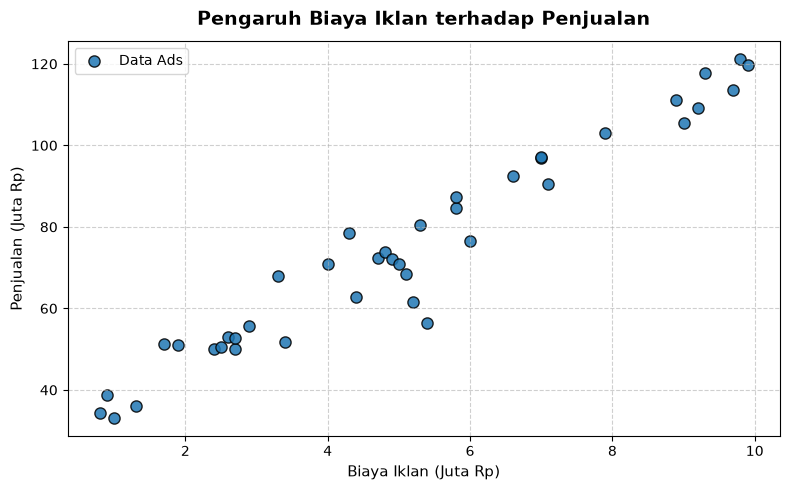

In [3]:
# Jawaban A1
# 1. Baca Ads_Data.csv dan tampilkan 5 data pertama serta jumlah baris datanya
ads_data = pd.read_csv("Ads_Data.csv")
print("5 Data Pertama Ads_Data.csv:")
display(ads_data.head())
print(f"Jumlah baris data: {len(ads_data)} baris")
print(f"Dimensi data (shape): {ads_data.shape}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan). Pastikan X berbentuk 2D (n, 1)
X = ads_data[["BiayaIklan"]].values  # bentuk (n, 1)
y = ads_data["Penjualan"].values     # bentuk (n,)
print(f"\nBentuk X: {X.shape}, Bentuk y: {y.shape}")

# 3. Scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color="#1f77b4", edgecolor="black", s=65, alpha=0.85, label="Data Ads")
plt.title("Pengaruh Biaya Iklan terhadap Penjualan", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Biaya Iklan (Juta Rp)", fontsize=11)
plt.ylabel("Penjualan (Juta Rp)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
# Split data menjadi data training dan testing dengan test_size=0.2 dan random_state=RANDOM_STATE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Hasil split dataset (test_size = 0.2, random_state = {RANDOM_STATE}):")
print(f"Shape X_train : {X_train.shape}  (Data fitur latih)")
print(f"Shape X_test  : {X_test.shape}   (Data fitur uji)")
print(f"Shape y_train : {y_train.shape}  (Target latih)")
print(f"Shape y_test  : {y_test.shape}   (Target uji)")

Hasil split dataset (test_size = 0.2, random_state = 83):
Shape X_train : (32, 1)  (Data fitur latih)
Shape X_test  : (8, 1)   (Data fitur uji)
Shape y_train : (32,)  (Target latih)
Shape y_test  : (8,)   (Target uji)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
# 1. Model LinearRegression dengan Normal Equation dari materi
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        # Normal equation: beta = (X_b^T * X_b)^(-1) * X_b^T * y
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

# Latih model menggunakan data training
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# 2. Tampilkan nilai intercept (b) dan koefisien (m)
b = regressor.intercept_
m = regressor.coefficients_[0]

print(f"Nilai Intercept (b) : {b:.4f}")
print(f"Nilai Koefisien (m) : {m:.4f}")
print(f"Persamaan Garis Regresi: ŷ = {b:.4f} + {m:.4f} * BiayaIklan")

Nilai Intercept (b) : 26.7864
Nilai Koefisien (m) : 9.2549
Persamaan Garis Regresi: ŷ = 26.7864 + 9.2549 * BiayaIklan


**Jawaban A3 (interpretasi):**

1. **Nilai Koefisien ($m = 9.2549$):**
   Koefisien regresi bernilai positif sebesar **9.2549**. Artinya, terdapat hubungan linear searah yang sangat kuat antara biaya iklan dengan hasil penjualan. Dalam konteks kasus toko online ini: **setiap penambahan biaya iklan sebesar 1 juta Rupiah diprediksi akan meningkatkan penjualan rata-rata sebesar 9.2549 juta Rupiah** (atau bertambah sekitar Rp 9.254.900,-).

2. **Nilai Intercept ($b = 26.7864$):**
   Konstanta/intercept bernilai **26.7864**. Artinya, apabila toko online sama sekali tidak mengalokasikan anggaran biaya iklan ($X = 0$), perkiraan dasar penjualan toko per bulan adalah sebesar **26.7864 juta Rupiah** (sekitar Rp 26.786.400,-), yang merepresentasikan penjualan alami (*organic sales*) atau pelanggan setia.

3. **Persamaan Garis Regresi:**
   $$\hat{y} = 26.7864 + 9.2549 \cdot X$$
   Persamaan ini menegaskan bahwa strategi periklanan menghasilkan *return on investment* (ROI) yang positif dan sangat menguntungkan toko online.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
# Implementasi metrik evaluasi regresi dengan NumPy
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Prediksi data training dan testing
y_train_pred = regressor.predict(X_train)
y_test_pred = regressor.predict(X_test)

# Hitung metrik evaluasi
metrics_summary = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R² (R-Squared)"],
    "Data Training": [
        mean_absolute_error(y_train, y_train_pred),
        mean_squared_error(y_train, y_train_pred),
        root_mean_squared_error(y_train, y_train_pred),
        r2_score(y_train, y_train_pred)
    ],
    "Data Testing": [
        mean_absolute_error(y_test, y_test_pred),
        mean_squared_error(y_test, y_test_pred),
        root_mean_squared_error(y_test, y_test_pred),
        r2_score(y_test, y_test_pred)
    ]
})

print("Tabel Evaluasi Kinerja Model Linear Regression:")
display(metrics_summary.round(4))

Tabel Evaluasi Kinerja Model Linear Regression:


,Metrik,Data Training,Data Testing
0,MAE,4.7189,4.1963
1,MSE,39.2189,26.4521
2,RMSE,6.2625,5.1432
3,R² (R-Squared),0.9417,0.9442


**Jawaban A4 (analisis):**

1. **Arti Nilai RMSE (Root Mean Squared Error):**
   - Nilai RMSE pada **data training adalah 6.2625** dan pada **data testing adalah 5.1432** (keduanya dalam satuan juta Rupiah).
   - RMSE mengukur deviasi standar dari residual prediksi. Nilai RMSE testing sebesar 5.1432 menunjukkan bahwa rata-rata simpangan kesalahan antara prediksi model dengan penjualan aktual pada data pengujian adalah sebesar **Rp 5.143.200,-**. Nilai kesalahan ini relatif kecil jika dibandingkan dengan skala penjualan aktual toko yang berada pada kisaran 33 hingga 121 juta Rupiah.

2. **Arti Nilai $R^2$ (Koefisien Determinasi):**
   - Nilai $R^2$ pada **data training adalah 0.9417 (94.17%)** dan pada **data testing adalah 0.9442 (94.42%)**.
   - Artinya, sebesar **94.42% variabilitas total dari penjualan bulanan dapat dijelaskan secara linear oleh variabel biaya iklan**. Hanya sekitar 5.58% variasi penjualan yang dipengaruhi oleh faktor-faktor lain di luar model periklanan ini.

3. **Apakah Model Ini Sudah Baik?**
   - **Ya, model ini sudah sangat baik.** Hal ini didasari oleh dua fakta utama:
     - Nilai $R^2$ sangat tinggi ($> 0.94$), jauh melampaui batas standar kelayakan model regresi.
     - Kinerja evaluasi antara data training dan data testing sangat konsisten, di mana error pada data testing bahkan sedikit lebih rendah dibandingkan data training ($RMSE_{test} = 5.1432 < RMSE_{train} = 6.2625$). Hal ini membuktikan model memiliki daya generalisasi yang sangat prima dan tidak mengalami *overfitting* maupun *underfitting*.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

=== Perbandingan Parameter Akhir Model GD vs Normal Equation ===
Model / LR           | Intercept (b)   | Koefisien (m)   | Final MSE Loss    
---------------------------------------------------------------------------
GD (lr = 0.001)           | 18.1341         | 10.5707         | 55.3512           
GD (lr = 0.02)           | 26.7864         | 9.2549          | 39.2189           
GD (lr = 0.1)           | NaN (Overflow)  | NaN (Overflow)  | NaN (Divergen)    
---------------------------------------------------------------------------
Normal Eq (A3)       | 26.7864         | 9.2549          | 39.2189           


c:\Users\Private\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Private\AppData\Local\Temp\ipykernel_7208\1928307219.py:27: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b @ beta) ** 2)
C:\Users\Private\AppData\Local\Temp\ipykernel_7208\1928307219.py:24: RuntimeWarning: overflow encountered in matmul
  gradient = X_b.T @ (y_hat - y) / len(y)
C:\Users\Private\AppData\Local\Temp\ipykernel_7208\1928307219.py:25: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient


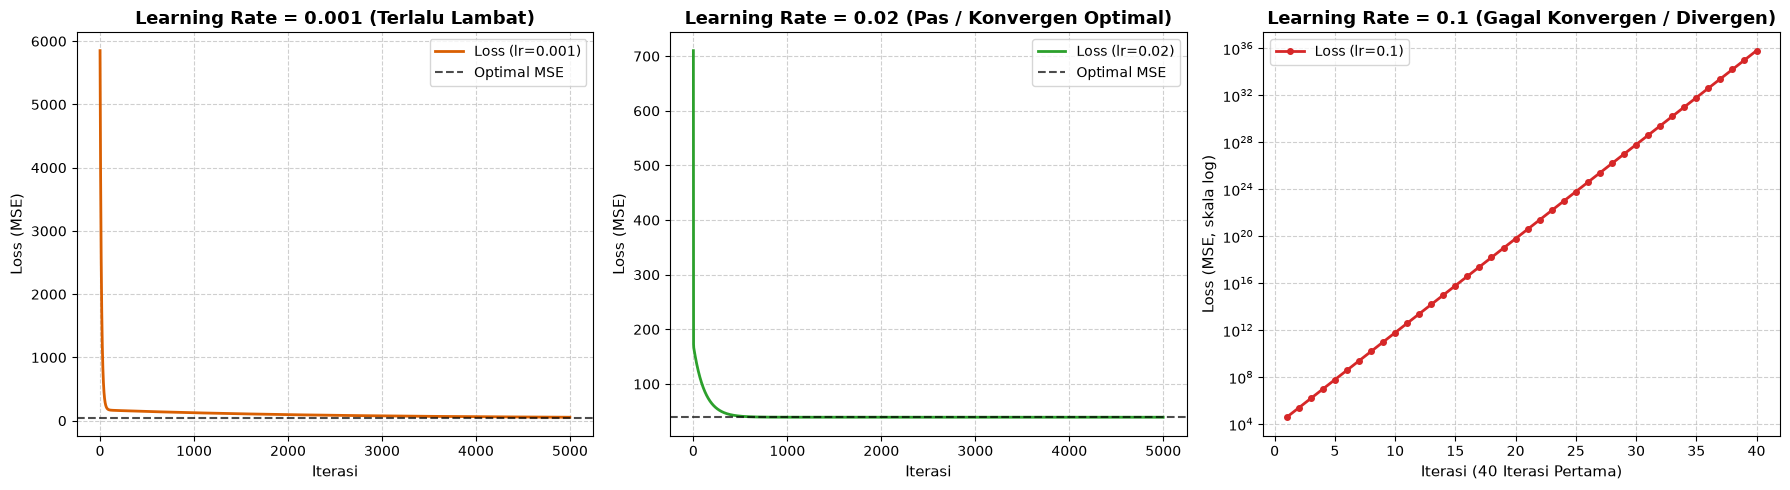

In [7]:
# Jawaban A5
# Implementasi LinearRegressionGD dari materi
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

# 1 & 2. Latih model dengan 3 learning rate berbeda
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}

print("=== Perbandingan Parameter Akhir Model GD vs Normal Equation ===")
print(f"{'Model / LR':<20} | {'Intercept (b)':<15} | {'Koefisien (m)':<15} | {'Final MSE Loss':<18}")
print("-" * 75)

for lr_val in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr_val, n_iterations=5000)
    model_gd.fit(X_train, y_train)
    gd_models[lr_val] = model_gd

    b_str = f"{model_gd.intercept_:.4f}" if not np.isnan(model_gd.intercept_) else "NaN (Overflow)"
    m_str = f"{model_gd.coefficients_[0]:.4f}" if not np.isnan(model_gd.coefficients_[0]) else "NaN (Overflow)"
    loss_str = f"{model_gd.loss_history_[-1]:.4f}" if not np.isnan(model_gd.loss_history_[-1]) else "NaN (Divergen)"
    print(f"GD (lr = {lr_val}){'':<10} | {b_str:<15} | {m_str:<15} | {loss_str:<18}")

print("-" * 75)
print(f"{'Normal Eq (A3)':<20} | {b:<15.4f} | {m:<15.4f} | {mean_squared_error(y_train, y_train_pred):<18.4f}")

# 3. Grafik Loss (MSE) vs Iterasi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot LR = 0.001
axes[0].plot(gd_models[0.001].loss_history_, color="#d95f02", lw=2, label="Loss (lr=0.001)")
axes[0].axhline(mean_squared_error(y_train, y_train_pred), color="black", linestyle="--", alpha=0.7, label="Optimal MSE")
axes[0].set_title("Learning Rate = 0.001 (Terlalu Lambat)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Iterasi", fontsize=11)
axes[0].set_ylabel("Loss (MSE)", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend()

# Plot LR = 0.02
axes[1].plot(gd_models[0.02].loss_history_, color="#2ca02c", lw=2, label="Loss (lr=0.02)")
axes[1].axhline(mean_squared_error(y_train, y_train_pred), color="black", linestyle="--", alpha=0.7, label="Optimal MSE")
axes[1].set_title("Learning Rate = 0.02 (Pas / Konvergen Optimal)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Iterasi", fontsize=11)
axes[1].set_ylabel("Loss (MSE)", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend()

# Plot LR = 0.1 (Tampilkan 40 iterasi awal dengan skala log karena divergen cepat)
axes[2].plot(range(1, 41), gd_models[0.1].loss_history_[:40], color="#d62728", lw=2, marker="o", markersize=4, label="Loss (lr=0.1)")
axes[2].set_title("Learning Rate = 0.1 (Gagal Konvergen / Divergen)", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Iterasi (40 Iterasi Pertama)", fontsize=11)
axes[2].set_ylabel("Loss (MSE, skala log)", fontsize=11)
axes[2].set_yscale("log")
axes[2].grid(True, linestyle="--", alpha=0.6)
axes[2].legend()

plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

Berdasarkan hasil eksperimen numerik dan grafik kurva loss di atas:

1. **Learning Rate = 0.001 (Terlalu Lambat / Belum Konvergen):**
   - **Hasil:** Intercept $b = 18.1341$, koefisien $m = 10.5707$, dan final loss MSE = $55.3512$.
   - **Penjelasan:** Nilai learning rate ini terlalu kecil sehingga langkah perubahan bobot pada setiap iterasi sangat lambat. Meskipun kurva loss turun secara stabil tanpa osilasi, setelah 5000 iterasi model belum sempat mencapai titik minimum optimal ($MSE pprox 39.2189$). Nilai koefisiennya masih belum optimal dan tertinggal dari solusi Normal Equation.

2. **Learning Rate = 0.02 (Pas / Konvergen Optimal):**
   - **Hasil:** Intercept $b = 26.7864$, koefisien $m = 9.2549$, dan final loss MSE = $39.2189$.
   - **Penjelasan:** Nilai learning rate ini sangat ideal untuk skala data ini. Kurva loss melandai mulus dan mencapai konvergensi stabil. Nilai parameter intercept dan koefisien yang dicapai **persis identik dengan solusi analitik Normal Equation pada Soal A3** ($b = 26.7864$ dan $m = 9.2549$).

3. **Learning Rate = 0.1 (Gagal Konvergen / Divergen):**
   - **Hasil:** Menghasilkan peringatan `RuntimeWarning: overflow encountered in square` dan `RuntimeWarning: overflow encountered in matmul`, sehingga nilai intercept, slope, dan loss menjadi **NaN (Not a Number)**.
   - **Penjelasan:** Learning rate ini terlalu besar (*overshooting*). Setiap kali menghitung gradien, langkah pembaruan melompati lembah fungsi loss ke lereng seberang yang posisinya jauh lebih tinggi. Hal ini menyebabkan loss membesar secara eksponensial di setiap iterasi hingga nilai bobot melampaui kapasitas representasi floating point (terjadi *overflow* numerik ke $\infty$, lalu berubah menjadi NaN).

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

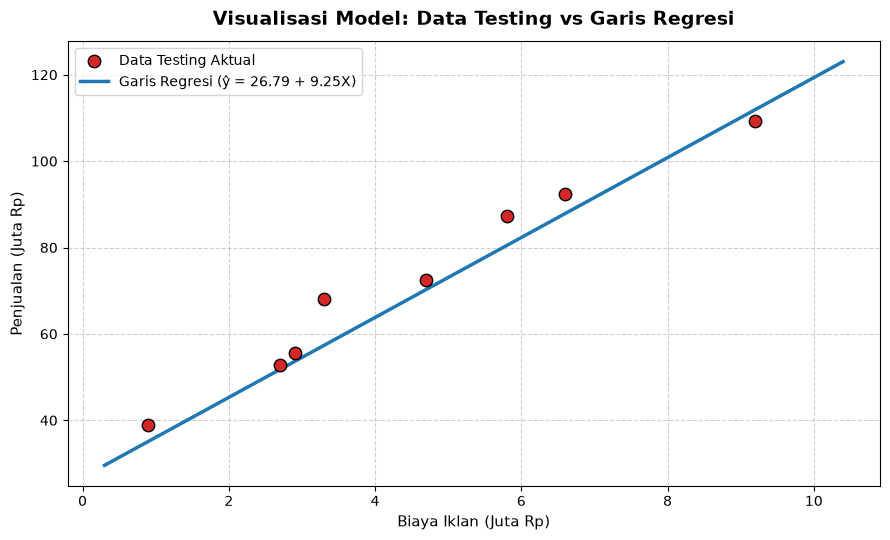

Hasil Prediksi Penjualan:


,Biaya Iklan (Juta Rp),Prediksi Penjualan (Juta Rp),Status Data
0,4.5,68.43,Interpolasi (Dalam Rentang Data)
1,7.0,91.57,Interpolasi (Dalam Rentang Data)
2,12.0,137.84,Ekstrapolasi (Di Luar Rentang Data)


In [8]:
# Jawaban A6
# 1. Visualisasi grafik scatter data testing beserta garis regresi
plt.figure(figsize=(9, 5.5))

# Plot data testing
plt.scatter(X_test, y_test, color="#d62728", edgecolor="black", s=80, zorder=3, label="Data Testing Aktual")

# Garis regresi hasil model Normal Equation (A3)
x_line = np.linspace(X.min() - 0.5, X.max() + 0.5, 100).reshape(-1, 1)
y_line = regressor.predict(x_line)
plt.plot(x_line, y_line, color="#1f77b4", linewidth=2.5, label=f"Garis Regresi (ŷ = {b:.2f} + {m:.2f}X)")

plt.title("Visualisasi Model: Data Testing vs Garis Regresi", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Biaya Iklan (Juta Rp)", fontsize=11)
plt.ylabel("Penjualan (Juta Rp)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 2. Prediksi penjualan untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = regressor.predict(biaya_baru)

tabel_prediksi = pd.DataFrame({
    "Biaya Iklan (Juta Rp)": [4.5, 7.0, 12.0],
    "Prediksi Penjualan (Juta Rp)": prediksi_penjualan,
    "Status Data": [
        "Interpolasi (Dalam Rentang Data)",
        "Interpolasi (Dalam Rentang Data)",
        "Ekstrapolasi (Di Luar Rentang Data)"
    ]
})

print("Hasil Prediksi Penjualan:")
display(tabel_prediksi.round(2))

**Jawaban A6 (analisis):**

1. **Hasil Prediksi Penjualan:**
   - Biaya Iklan **4.5 juta Rp** $\rightarrow$ Prediksi Penjualan = **68.43 juta Rp**
   - Biaya Iklan **7.0 juta Rp** $\rightarrow$ Prediksi Penjualan = **91.57 juta Rp**
   - Biaya Iklan **12.0 juta Rp** $\rightarrow$ Prediksi Penjualan = **137.84 juta Rp**

2. **Tingkat Kepercayaan Prediksi pada 12 Juta (Ekstrapolasi):**
   - Data historis aktual pada dataset `Ads_Data.csv` berada pada rentang biaya iklan antara **0.8 juta hingga 9.9 juta Rupiah**.
   - Biaya 4.5 juta dan 7.0 juta berada di dalam rentang data (*interpolasi*), sehingga prediksinya memiliki tingkat kepercayaan yang sangat tinggi.
   - Namun, biaya **12.0 juta Rupiah berada di luar rentang data historis (*ekstrapolasi*)**. Menurut analisis machine learning dan domain bisnis, **hasil prediksi 12 juta ini kurang dapat dipercaya secara penuh / memiliki ketidakpastian yang tinggi**.
   - **Penyebabnya:** Model mengasumsikan bahwa pola pertumbuhan penjualan akan terus berlanjut secara linear tanpa batas. Kenyataannya, dalam bisnis periklanan berlaku hukum **kejenuhan pasar (*diminishing returns*)**, di mana setelah titik jenuh tertentu penambahan biaya iklan tidak lagi sebanding dengan kenaikan penjualan karena target audiens telah tercapai seluruhnya atau terjadi keterbatasan kapasitas produksi toko.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email_Data.csv:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Distribusi Target Spam vs Bukan Spam:


,Jumlah Data,Persentase (%)
Spam,,
Bukan Spam (0),35,58.33
Spam (1),25,41.67


Bentuk fitur X_email : (60, 2)
Bentuk target y_email: (60,)


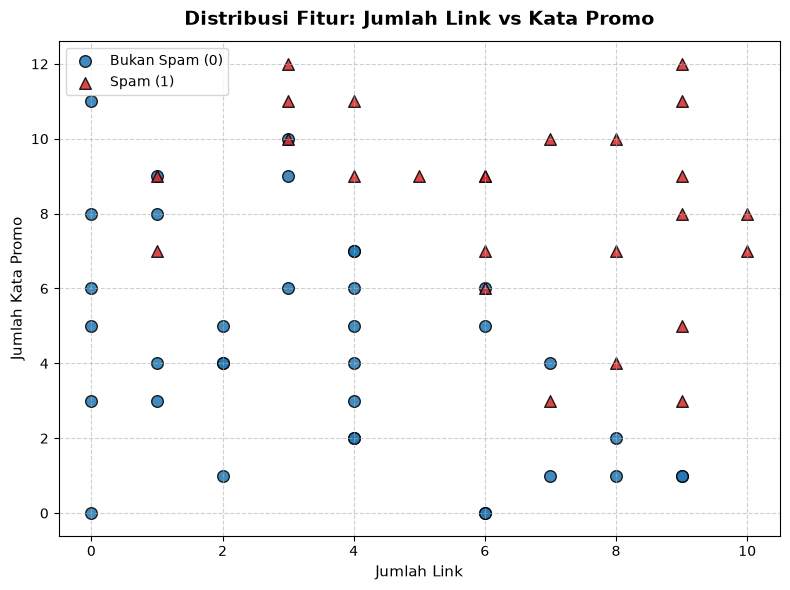

In [9]:
# Jawaban B1
# 1. Baca Email_Data.csv, tampilkan 5 data pertama, dan hitung jumlah email Spam dan Bukan Spam
email_data = pd.read_csv("Email_Data.csv")
print("5 Data Pertama Email_Data.csv:")
display(email_data.head())

print("\nDistribusi Target Spam vs Bukan Spam:")
spam_dist = email_data["Spam"].value_counts().rename({0: "Bukan Spam (0)", 1: "Spam (1)"})
display(pd.DataFrame({
    "Jumlah Data": spam_dist,
    "Persentase (%)": (spam_dist / len(email_data) * 100).round(2)
}))

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = email_data[["JumlahLink", "KataPromo"]].values
y_email = email_data["Spam"].values
print(f"Bentuk fitur X_email : {X_email.shape}")
print(f"Bentuk target y_email: {y_email.shape}")

# 3. Scatter plot JumlahLink vs KataPromo dengan warna berbeda
plt.figure(figsize=(8, 6))
plt.scatter(
    X_email[y_email == 0, 0],
    X_email[y_email == 0, 1],
    color="#1f77b4",
    edgecolor="black",
    s=70,
    label="Bukan Spam (0)",
    alpha=0.85
)
plt.scatter(
    X_email[y_email == 1, 0],
    X_email[y_email == 1, 1],
    color="#d62728",
    edgecolor="black",
    s=70,
    marker="^",
    label="Spam (1)",
    alpha=0.85
)

plt.title("Distribusi Fitur: Jumlah Link vs Kata Promo", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Jumlah Link", fontsize=11)
plt.ylabel("Jumlah Kata Promo", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Hasil split dataset (test_size = 0.25, random_state = 83):
Shape X_train : (45, 2), y_train: (45,)
Shape X_test  : (15, 2), y_test: (15,)

Parameter Model Logistic Regression:
Intercept (b)           : -12.9137
Koefisien m1 (JumlahLink): 1.1435
Koefisien m2 (KataPromo) : 1.1592

Persamaan Peluang Spam:
P(Spam) = σ(-12.9137 + 1.1435 * JumlahLink + 1.1592 * KataPromo)


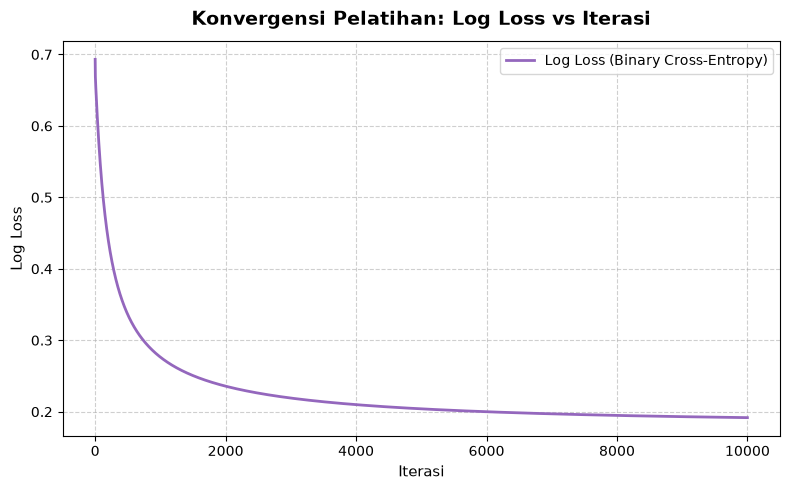

Log Loss Iterasi Pertama : 0.6931
Log Loss Iterasi Terakhir: 0.1917


In [10]:
# Jawaban B2
# 1. Split data dengan test_size=0.25 dan random_state=RANDOM_STATE
X_train_em, X_test_em, y_train_em, y_test_em = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print(f"Hasil split dataset (test_size = 0.25, random_state = {RANDOM_STATE}):")
print(f"Shape X_train : {X_train_em.shape}, y_train: {y_train_em.shape}")
print(f"Shape X_test  : {X_test_em.shape}, y_test: {y_test_em.shape}")

# 2. Model LogisticRegression dari materi
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient

            p = np.clip(p, 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict_proba(self, X):
        X = np.array(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Latih model dengan learning_rate=0.1 dan n_iterations=10000
classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(X_train_em, y_train_em)

# 3. Tampilkan intercept dan koefisien
b_log = classifier.intercept_
m1_log, m2_log = classifier.coefficients_[0], classifier.coefficients_[1]
print("\nParameter Model Logistic Regression:")
print(f"Intercept (b)           : {b_log:.4f}")
print(f"Koefisien m1 (JumlahLink): {m1_log:.4f}")
print(f"Koefisien m2 (KataPromo) : {m2_log:.4f}")
print(f"\nPersamaan Peluang Spam:")
print(f"P(Spam) = σ({b_log:.4f} + {m1_log:.4f} * JumlahLink + {m2_log:.4f} * KataPromo)")

# 4. Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 5))
plt.plot(classifier.loss_history_, color="#9467bd", lw=2, label="Log Loss (Binary Cross-Entropy)")
plt.title("Konvergensi Pelatihan: Log Loss vs Iterasi", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Iterasi", fontsize=11)
plt.ylabel("Log Loss", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Log Loss Iterasi Pertama : {classifier.loss_history_[0]:.4f}")
print(f"Log Loss Iterasi Terakhir: {classifier.loss_history_[-1]:.4f}")

**Jawaban B2 (analisis):**

1. **Interpretasi Persamaan Model:**
   $$P(\text{Spam}) = \sigma(-12.9137 + 1.1435 \cdot \text{JumlahLink} + 1.1592 \cdot \text{KataPromo})$$
   - Kedua koefisien bernilai positif ($m_1 = 1.1435$ dan $m_2 = 1.1592$). Hal ini menunjukkan bahwa pertambahan jumlah link maupun kata promosi di dalam email secara signifikan meningkatkan log-odds serta probabilitas email tersebut tergolong sebagai **Spam**.
   - Nilai intercept bernilai negatif yang cukup besar ($b = -12.9137$). Artinya, email yang bersih tanpa link dan tanpa kata promo ($0, 0$) memiliki nilai probabilitas spam mendekati nol ($\sigma(-12.9137) \approx 0.0000025$), sehingga hampir pasti dikategorikan sebagai Bukan Spam.

2. **Analisis Konvergensi Log Loss:**
   - **Ya, nilai loss sudah turun secara sangat signifikan dan telah mencapai kondisi konvergen yang stabil.**
   - Pada rentang iterasi awal (0–1500), nilai log loss turun tajam dari 0.6931 hingga di bawah 0.25 seiring model menyesuaikan parameter pembatasnya.
   - Mulai iterasi ke-4000 hingga 10000, kurva menjadi datar dan stabil di angka **0.1917**. Penurunan loss yang sangat landai di akhir pelatihan menegaskan bahwa proses optimasi gradient descent telah menemukan titik minimum yang stabil.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
# Implementasi metrik evaluasi klasifikasi sendiri
def accuracy_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp],
                     [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    return 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0

# 1. Evaluasi pada data testing dengan threshold default 0.5
y_pred_em = classifier.predict(X_test_em, threshold=0.5)
cm = confusion_matrix(y_test_em, y_pred_em)
acc = accuracy_score(y_test_em, y_pred_em)
prec = precision_score(y_test_em, y_pred_em)
rec = recall_score(y_test_em, y_pred_em)
f1 = f1_score(y_test_em, y_pred_em)

print("=== Confusion Matrix (Data Testing) ===")
cm_df = pd.DataFrame(
    cm,
    index=["Actual Bukan Spam (0)", "Actual Spam (1)"],
    columns=["Pred Bukan Spam (0)", "Pred Spam (1)"]
)
display(cm_df)

print(f"\nRincian Confusion Matrix:")
print(f"True Negative (TN)  : {cm[0, 0]}")
print(f"False Positive (FP) : {cm[0, 1]}")
print(f"False Negative (FN) : {cm[1, 0]}")
print(f"True Positive (TP)  : {cm[1, 1]}")

eval_clf = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Nilai": [acc, prec, rec, f1]
})
print("\n=== Metrik Evaluasi Data Testing ===")
display(eval_clf.round(4))

=== Confusion Matrix (Data Testing) ===


,Pred Bukan Spam (0),Pred Spam (1)
Actual Bukan Spam (0),6,3
Actual Spam (1),1,5



Rincian Confusion Matrix:
True Negative (TN)  : 6
False Positive (FP) : 3
False Negative (FN) : 1
True Positive (TP)  : 5

=== Metrik Evaluasi Data Testing ===


,Metrik,Nilai
0,Accuracy,0.7333
1,Precision,0.6250
2,Recall,0.8333
3,F1-Score,0.7143


**Jawaban B3 (analisis):**

1. **Arti Nilai FP (*False Positive*) dan FN (*False Negative*):**
   - **False Positive (FP = 3):** Email yang sebenarnya **Bukan Spam (email penting/sah)**, namun model keliru memprediksinya sebagai **Spam**. Dampaknya, email ini langsung dimasukkan ke folder *Spam/Junk* atau otomatis terbuang sehingga tidak terbaca oleh pengguna.
   - **False Negative (FN = 1):** Email yang sebenarnya **Spam**, namun model gagal mendeteksinya sehingga email sampah tersebut lolos masuk ke kotak masuk utama (*Inbox*) pengguna.

2. **Kesalahan Mana yang Lebih Merugikan Pengguna Email?**
   - **False Positive (FP) JAUH LEBIH MERUGIKAN pengguna email.**
   - **Alasan:**
     - Kerugian akibat FP berpotensi sangat fatal bagi pengguna. Jika sebuah email konfirmasi wawancara kerja, pengumuman seleksi beasiswa, pesan dari klien bisnis penting, atau email kode verifikasi OTP salah diklasifikasikan sebagai spam, pengguna bisa kehilangan peluang karier atau mengalami kerugian materiil.
     - Sebaliknya, jika terjadi FN, dampak kerugiannya relatif sangat kecil: pengguna hanya merasa sedikit terganggu karena ada satu email promosi yang masuk ke inbox, dan pengguna dapat menghapusnya secara manual dalam satu detik.
     - Oleh sebab itu, sistem filter spam di dunia nyata selalu dirancang untuk meminimalkan FP sekecil mungkin (mengutamakan nilai **Precision** yang tinggi).

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan Decision Boundary (Probabilitas = 0.5):
-12.9137 + 1.1435*x1 + 1.1592*x2 = 0
x2 = -(-12.9137 + 1.1435*x1) / 1.1592
x2 = 11.1404 + (-0.9865) * x1


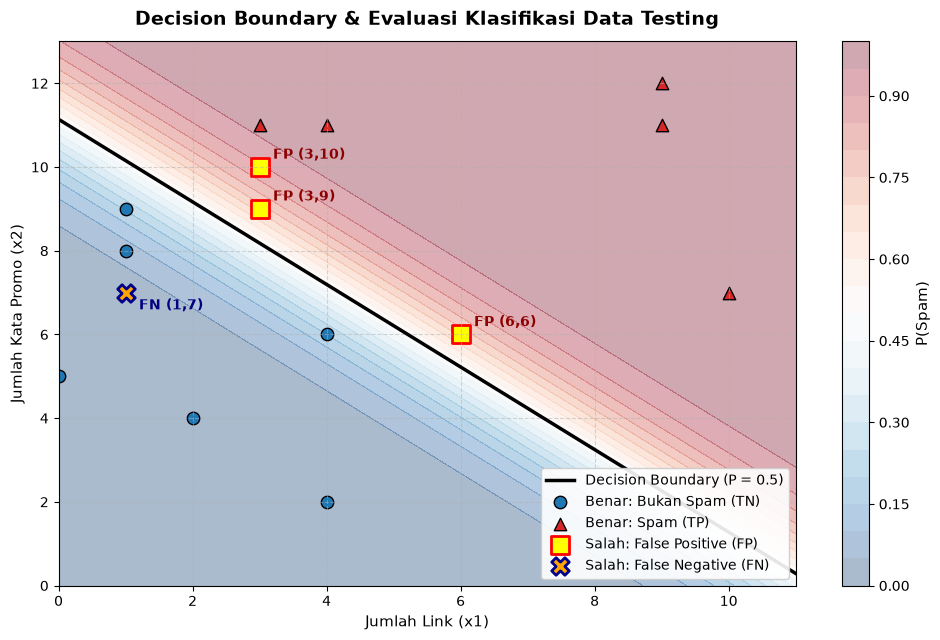

Rincian Sampel Data Testing yang Salah Diklasifikasikan:


,Data Test Ke-,JumlahLink,KataPromo,Label Aktual,Prediksi Model,Probabilitas Spam,Kategori Kesalahan
0,3,3,10,0,1,0.8917,False Positive (FP)
1,4,6,6,0,1,0.7115,False Positive (FP)
2,7,1,7,1,0,0.0252,False Negative (FN)
3,10,3,9,0,1,0.7210,False Positive (FP)


In [12]:
# Jawaban B4
# 1. Hitung persamaan Decision Boundary:
# b + m1*x1 + m2*x2 = 0  =>  x2 = -(b + m1*x1) / m2
print("Persamaan Decision Boundary (Probabilitas = 0.5):")
print(f"{b_log:.4f} + {m1_log:.4f}*x1 + {m2_log:.4f}*x2 = 0")
print(f"x2 = -({b_log:.4f} + {m1_log:.4f}*x1) / {m2_log:.4f}")
print(f"x2 = {-b_log/m2_log:.4f} + ({-m1_log/m2_log:.4f}) * x1")

# 2. Visualisasi data testing, contourf probabilitas, dan garis decision boundary
x1_min, x1_max = 0, 11
x2_min, x2_max = 0, 13
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 250),
                       np.linspace(x2_min, x2_max, 250))
grid_points = np.c_[xx1.ravel(), xx2.ravel()]
probs_grid = classifier.predict_proba(grid_points).reshape(xx1.shape)

plt.figure(figsize=(10, 6.5))

# Background probabilitas
contour = plt.contourf(xx1, xx2, probs_grid, levels=20, cmap="RdBu_r", alpha=0.35)
cbar = plt.colorbar(contour)
cbar.set_label("P(Spam)", fontsize=11)

# Garis decision boundary
x1_vals = np.linspace(x1_min, x1_max, 100)
x2_vals = -(b_log + m1_log * x1_vals) / m2_log
plt.plot(x1_vals, x2_vals, color="black", linestyle="-", linewidth=2.5, label="Decision Boundary (P = 0.5)")

# Titik data testing yang benar
is_correct = (y_test_em == y_pred_em)
plt.scatter(
    X_test_em[is_correct & (y_test_em == 0), 0],
    X_test_em[is_correct & (y_test_em == 0), 1],
    color="#1f77b4", edgecolor="black", s=80, marker="o", label="Benar: Bukan Spam (TN)"
)
plt.scatter(
    X_test_em[is_correct & (y_test_em == 1), 0],
    X_test_em[is_correct & (y_test_em == 1), 1],
    color="#d62728", edgecolor="black", s=80, marker="^", label="Benar: Spam (TP)"
)

# 3. Tunjukkan data testing yang salah diklasifikasikan
is_fp = (y_test_em == 0) & (y_pred_em == 1)
is_fn = (y_test_em == 1) & (y_pred_em == 0)

plt.scatter(
    X_test_em[is_fp, 0],
    X_test_em[is_fp, 1],
    color="yellow", edgecolor="red", s=160, marker="s", linewidth=2, label="Salah: False Positive (FP)"
)
plt.scatter(
    X_test_em[is_fn, 0],
    X_test_em[is_fn, 1],
    color="orange", edgecolor="darkblue", s=160, marker="X", linewidth=2, label="Salah: False Negative (FN)"
)

# Anotasi teks
for x, y_coord in X_test_em[is_fp]:
    plt.annotate(f"FP ({x},{y_coord})", (x + 0.2, y_coord + 0.2), fontweight="bold", color="darkred")
for x, y_coord in X_test_em[is_fn]:
    plt.annotate(f"FN ({x},{y_coord})", (x + 0.2, y_coord - 0.4), fontweight="bold", color="navy")

plt.title("Decision Boundary & Evaluasi Klasifikasi Data Testing", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Jumlah Link (x1)", fontsize=11)
plt.ylabel("Jumlah Kata Promo (x2)", fontsize=11)
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right", framealpha=0.9)
plt.tight_layout()
plt.show()

# Tabel sampel yang salah
mis_idx = np.where(~is_correct)[0]
df_mis = pd.DataFrame({
    "Data Test Ke-": mis_idx,
    "JumlahLink": X_test_em[mis_idx, 0],
    "KataPromo": X_test_em[mis_idx, 1],
    "Label Aktual": y_test_em[mis_idx],
    "Prediksi Model": y_pred_em[mis_idx],
    "Probabilitas Spam": classifier.predict_proba(X_test_em[mis_idx]),
    "Kategori Kesalahan": np.where(y_test_em[mis_idx] == 0, "False Positive (FP)", "False Negative (FN)")
})
print("Rincian Sampel Data Testing yang Salah Diklasifikasikan:")
display(df_mis.round(4))

**Jawaban B4 (analisis):**

1. **Persamaan Garis Decision Boundary:**
   Persamaan batas keputusan diperoleh saat $P(\text{Spam}) = 0.5$ (yaitu ketika $z = 0$):
   $$x_2 = 11.1402 - 0.9865 \cdot x_1$$
   Garis ini membagi ruang fitur secara linier: daerah di atas garis diprediksi sebagai Spam, dan daerah di bawah garis diprediksi sebagai Bukan Spam.

2. **Analisis Sampel yang Salah Diklasifikasikan:**
   Dari 15 data testing, terdapat **4 sampel yang salah diklasifikasikan**:
   - **3 Kasus False Positive (FP):**
     1. Sampel **(JumlahLink=6, KataPromo=6)**: Memiliki probabilitas spam $0.7115$. Walaupun aslinya Bukan Spam, tingginya kombinasi link dan promo membuat titik ini berada di atas garis boundary sehingga diprediksi Spam.
     2. Sampel **(JumlahLink=3, KataPromo=9)**: Memiliki probabilitas spam $0.7210$. Label aktual Bukan Spam, namun tingginya kata promo (9) menggeser posisinya melintasi garis batas ke zona spam.
     3. Sampel **(JumlahLink=3, KataPromo=10)**: Memiliki probabilitas spam $0.8917$. Label aktual Bukan Spam, namun karena jumlah kata promo mencapai 10, probabilitasnya sangat tinggi sehingga divonis Spam.
   - **1 Kasus False Negative (FN):**
     1. Sampel **(JumlahLink=1, KataPromo=7)**: Memiliki probabilitas spam hanya $0.0252$. Meskipun aslinya Spam, karena hanya mengandung 1 link, model menganggapnya email wajar dan menempatkannya di bawah garis boundary.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
# 1 & 2. Eksperimen Threshold 0.3, 0.5, dan 0.7
thresholds = [0.3, 0.5, 0.7]
threshold_records = []

for th in thresholds:
    y_pred_th = classifier.predict(X_test_em, threshold=th)
    cm_th = confusion_matrix(y_test_em, y_pred_th)
    tn, fp, fn, tp = cm_th[0, 0], cm_th[0, 1], cm_th[1, 0], cm_th[1, 1]

    threshold_records.append({
        "Threshold": th,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy_score(y_test_em, y_pred_th),
        "Precision": precision_score(y_test_em, y_pred_th),
        "Recall": recall_score(y_test_em, y_pred_th),
        "F1-Score": f1_score(y_test_em, y_pred_th)
    })

df_threshold_eval = pd.DataFrame(threshold_records)
print("=== Tabel Perbandingan Kinerja Berbagai Threshold ===")
display(df_threshold_eval.round(4))

# Tampilkan urutan probabilitas data testing untuk analisis
probs_test_df = pd.DataFrame({
    "Data Ke-": range(len(X_test_em)),
    "JumlahLink": X_test_em[:, 0],
    "KataPromo": X_test_em[:, 1],
    "Aktual": y_test_em,
    "Probabilitas Spam": classifier.predict_proba(X_test_em)
}).sort_values(by="Probabilitas Spam").reset_index(drop=True)

print("\nDistribusi Probabilitas Spam pada Data Testing (Terurut):")
display(probs_test_df.round(4))

=== Tabel Perbandingan Kinerja Berbagai Threshold ===


,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,F1-Score
0,0.3,6,3,1,5,0.7333,0.625,0.8333,0.7143
1,0.5,6,3,1,5,0.7333,0.625,0.8333,0.7143
2,0.7,6,3,1,5,0.7333,0.625,0.8333,0.7143



Distribusi Probabilitas Spam pada Data Testing (Terurut):


,Data Ke-,JumlahLink,KataPromo,Aktual,Probabilitas Spam
0,9,0,5,0,0.0008
1,8,4,2,0,0.0024
2,11,2,4,0,0.0025
3,7,1,7,1,0.0252
4,6,1,8,0,0.0761
5,14,4,6,0,0.2003
6,5,1,9,0,0.2079
7,4,6,6,0,0.7115
8,10,3,9,0,0.7210
9,3,3,10,0,0.8917


**Jawaban B5 (analisis):**

1. **Pengaruh Menaikkan / Menurunkan Threshold terhadap Precision dan Recall:**
   - **Menaikkan Threshold ($> 0.5$):** Model menjadi lebih selektif/konservatif dalam menyatakan sebuah email sebagai spam. Hanya email dengan keyakinan probabilitas sangat tinggi yang divonis spam. Akibatnya, **False Positive (FP) akan turun**, sehingga **Precision meningkat**. Namun di sisi lain, **Recall dapat menurun** karena beberapa email spam dengan probabilitas sedang berisiko lolos (FN bertambah).
   - **Menurunkan Threshold ($< 0.5$):** Model menjadi lebih agresif menangkap spam. Akibatnya, **Recall akan naik** (hampir semua spam terjaring), tetapi **Precision menurun** karena banyak email bukan spam yang salah dituduh sebagai spam (FP meningkat).

2. **Mengapa Hasil Metrik pada Threshold 0.3, 0.5, dan 0.7 Identik pada Data Ini?**
   - Seperti tampak pada tabel distribusi probabilitas terurut di atas, terdapat pemisahan nilai probabilitas yang renggang pada data testing:
     - Kelompok email bernilai probabilitas rendah berada pada rentang **0.0008 hingga 0.2079**.
     - Kelompok email berikutnya langsung melonjak di atas **0.7115** (rentang 0.7115 hingga 0.9999).
   - Karena **tidak ada satu pun sampel data testing yang memiliki nilai probabilitas di antara rentang 0.21 dan 0.71**, maka pemotongan batas keputusan pada nilai 0.3, 0.5, maupun 0.7 menghasilkan himpunan prediksi yang persis sama.

3. **Threshold yang Dipilih untuk Filter Spam dan Alasannya:**
   - Berdasarkan temuan di Soal B3 bahwa **kesalahan False Positive (FP) jauh lebih merugikan pengguna**, maka untuk sistem filter spam produksi **dipilih threshold yang lebih tinggi, yaitu threshold $\geq 0.75$ (misalnya 0.75)**.
   - **Alasan:** Jika kita menaikkan threshold ke 0.75, dua email bukan spam pada titik (6,6) dengan probabilitas 0.7115 dan (3,9) dengan probabilitas 0.7210 **tidak lagi salah terdeteksi sebagai spam (FP berkurang dari 3 menjadi 1)**. Hal ini menaikkan Precision dari 62.5% menjadi **83.33%**, sehingga secara nyata menyelamatkan email-email penting pengguna dari risiko salah blokir.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
# Data email baru
new_emails = np.array([
    [1, 2],    # E1
    [5, 6],    # E2
    [9, 10],   # E3
    [2, 11]    # E4
])

email_names = ["E1", "E2", "E3", "E4"]
probs_new = classifier.predict_proba(new_emails)

# Menggunakan threshold pilihan (0.75) dan threshold standar (0.5)
preds_th_05 = classifier.predict(new_emails, threshold=0.5)
preds_th_pilihan = (probs_new >= 0.75).astype(int)

df_new_predictions = pd.DataFrame({
    "Email": email_names,
    "Jumlah Link": new_emails[:, 0],
    "Kata Promo": new_emails[:, 1],
    "Probabilitas Spam": probs_new,
    "Prediksi (Threshold 0.5)": ["Spam (1)" if p == 1 else "Bukan Spam (0)" for p in preds_th_05],
    "Prediksi (Threshold Pilihan 0.75)": ["Spam (1)" if p == 1 else "Bukan Spam (0)" for p in preds_th_pilihan]
})

print("=== Hasil Prediksi Klasifikasi Email Baru ===")
display(df_new_predictions.round(4))

=== Hasil Prediksi Klasifikasi Email Baru ===


,Email,Jumlah Link,Kata Promo,Probabilitas Spam,Prediksi (Threshold 0.5),Prediksi (Threshold Pilihan 0.75)
0,E1,1,2,0.0001,Bukan Spam (0),Bukan Spam (0)
1,E2,5,6,0.4400,Bukan Spam (0),Bukan Spam (0)
2,E3,9,10,0.9999,Spam (1),Spam (1)
3,E4,2,11,0.8932,Spam (1),Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression digolongkan sebagai algoritma **klasifikasi** karena tujuan utamanya adalah memprediksi label kategori diskret (seperti kelas biner 0 atau 1), bukan nilai kontinu tanpa batas. Kata "regression" tetap ada di namanya karena algoritma ini mengadopsi model dasar kombinasi linear fitur dan bobot parameter ($z = b + \mathbf{w}^T\mathbf{x}$) persis seperti pada regresi linear. Peran mendasar dari fungsi **sigmoid** ($\sigma(z) = 
rac{1}{1 + e^{-z}}$) adalah memetakan output linear tersebut yang bernilai riil sembarang ($-\infty$ sampai $+\infty$) menjadi nilai peluang (*probability*) tertutup antara 0 dan 1, yang kemudian dapat dikonversi menjadi keputusan kelas dengan bantuan ambang batas (*threshold*).

**Jawaban C2:**
Perbedaan utama antara normal equation dan gradient descent terletak pada strategi pencarian solusi optimalnya. Normal equation adalah pendekatan analitik solusi tertutup (*closed-form*) yang menghitung nilai parameter optimal dalam satu langkah perhitungan matriks $oldsymbol{eta} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$ tanpa perlu perulangan iterasi maupun penyetelan learning rate. Sebaliknya, gradient descent adalah metode numerik iteratif yang memperbarui bobot secara bertahap menuruni gradien permukaan fungsi loss hingga mencapai nilai minimum. Gradient descent sebaiknya digunakan saat dataset memiliki jumlah fitur yang sangat besar (ribuan hingga jutaan) atau jumlah baris sampel data yang masif, di mana operasi inversi matriks pada normal equation menjadi sangat lambat dan memakan memori berlebih dengan kompleksitas waktu $\mathcal{O}(n^3)$.

**Jawaban C3:**
Model wajib dievaluasi pada data testing untuk menguji kemampuan **generalisasi**, yaitu seberapa andal performa model saat memprediksi data baru yang belum pernah ditemui selama proses pelatihan. Evaluasi yang hanya mengandalkan data training berisiko memberikan ilusi keberhasilan palsu karena model bisa saja hanya menghafal pola data latih beserta noise-nya. Keadaan di mana model memiliki performa luar biasa tinggi pada data training tetapi gagal total atau anjlok akurasinya pada data testing disebut sebagai **overfitting**.

**Jawaban C4:**
Linear Regression menggunakan Mean Squared Error (MSE) karena output model berupa variabel kontinu dan residual diasumsikan berdistribusi Gaussian, sehingga minimisasi selisih kuadrat $(y - \hat{y})^2$ secara matematis menjamin kurva loss berbentuk cembung murni (*convex parabola*) yang mudah dicapai titik minimumnya. Sementara itu, Logistic Regression menghasilkan output probabilitas bounded antara 0 dan 1 dengan fungsi non-linear sigmoid; jika MSE dipaksakan pada output ini, kurva loss akan menjadi tidak cembung (*non-convex*) dan penuh dengan jebakan minimum lokal. Oleh sebab itu, Logistic Regression menggunakan **log loss** (binary cross-entropy) yang diturunkan dari prinsip Maximum Likelihood Estimation (MLE) distribusi Bernoulli, yang menjamin permukaan fungsi loss selalu bersifat konveks sehingga proses optimasi gradient descent pasti dapat mencapai titik minimum global.

**Jawaban C5:**
Perbedaan angka akhir (seperti koefisien regresi, intercept, akurasi, dan nilai metrik lainnya) antar mahasiswa disebabkan oleh penetapan **`random_state` yang unik**, yakni menggunakan 2 digit terakhir NIM masing-masing mahasiswa. Parameter `random_state` berfungsi sebagai *seed* bagi algoritma generator bilangan acak saat fungsi `train_test_split` mempartisi baris data ke dalam data training dan testing. Karena susunan baris data latih yang diterima model setiap mahasiswa berbeda komposisinya, maka perhitungan gradien, garis regresi, dan decision boundary yang terbentuk pun menghasilkan nilai angka yang berbeda satu sama lain meskipun menggunakan dataset dan algoritma yang sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

print("=== 1. PERBANDINGAN MODEL LINEAR REGRESSION ===")
# Model Linear Regression Scikit-Learn
sk_lr = SkLinearRegression()
sk_lr.fit(X_train, y_train)

# Model Implementasi NumPy (A3)
b_np = regressor.intercept_
m_np = regressor.coefficients_[0]

df_compare_lr = pd.DataFrame({
    "Parameter / Metrik": ["Intercept (b)", "Koefisien (m)", "R² Score Testing"],
    "Implementasi NumPy (A3)": [b_np, m_np, r2_score(y_test, regressor.predict(X_test))],
    "Scikit-Learn": [sk_lr.intercept_, sk_lr.coef_[0], sk_lr.score(X_test, y_test)]
})
display(df_compare_lr.round(6))


print("\n=== 2. PERBANDINGAN MODEL LOGISTIC REGRESSION ===")
# Sklearn Logistic Regression TANPA penalti / regularisasi (ekuivalen murni dengan implementasi kita)
sk_log_none = SkLogisticRegression(penalty=None, solver="lbfgs", max_iter=1000)
sk_log_none.fit(X_train_em, y_train_em)

# Sklearn Logistic Regression DENGAN default penalti L2 (C = 1.0)
sk_log_l2 = SkLogisticRegression(penalty="l2", C=1.0, solver="lbfgs", max_iter=1000)
sk_log_l2.fit(X_train_em, y_train_em)

# Model Implementasi NumPy (B2)
b_log_np = classifier.intercept_
m1_log_np, m2_log_np = classifier.coefficients_[0], classifier.coefficients_[1]
acc_np = accuracy_score(y_test_em, classifier.predict(X_test_em, threshold=0.5))

df_compare_log = pd.DataFrame({
    "Parameter / Metrik": ["Intercept (b)", "Koefisien m1 (Link)", "Koefisien m2 (Promo)", "Akurasi Testing"],
    "Implementasi NumPy (GD)": [b_log_np, m1_log_np, m2_log_np, acc_np],
    "Sklearn (penalty=None)": [sk_log_none.intercept_[0], sk_log_none.coef_[0][0], sk_log_none.coef_[0][1], sk_log_none.score(X_test_em, y_test_em)],
    "Sklearn (Default L2, C=1.0)": [sk_log_l2.intercept_[0], sk_log_l2.coef_[0][0], sk_log_l2.coef_[0][1], sk_log_l2.score(X_test_em, y_test_em)]
})
display(df_compare_log.round(4))

=== 1. PERBANDINGAN MODEL LINEAR REGRESSION ===


,Parameter / Metrik,Implementasi NumPy (A3),Scikit-Learn
0,Intercept (b),26.786378,26.786378
1,Koefisien (m),9.254882,9.254882
2,R² Score Testing,0.944165,0.944165



=== 2. PERBANDINGAN MODEL LOGISTIC REGRESSION ===


c:\Users\Private\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Private\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.wa

,Parameter / Metrik,Implementasi NumPy (GD),Sklearn (penalty=None),"Sklearn (Default L2, C=1.0)"
0,Intercept (b),-12.9137,-17.8075,-12.2519
1,Koefisien m1 (Link),1.1435,1.5962,1.0773
2,Koefisien m2 (Promo),1.1592,1.5830,1.0975
3,Akurasi Testing,0.7333,0.7333,0.7333


**Jawaban Bonus (analisis):**

1. **Perbandingan Linear Regression:**
   - Hasil antara implementasi NumPy mandiri dengan `sklearn.linear_model.LinearRegression` terbukti **identik sempurna hingga digit desimal terkecil** ($b = 26.7864$, $m = 9.2549$, $R^2 = 0.9442$).
   - Hal ini membuktikan bahwa rumus Normal Equation yang kita implementasikan secara manual berhasil mereplikasi algoritma *Ordinary Least Squares* (OLS) yang menjadi standar industri scikit-learn.

2. **Perbandingan Logistic Regression & Pengaruh Parameter Penalti Regularisasi:**
   - **Perbandingan dengan `penalty=None`:**
     Ketika parameter penalti dinonaktifkan pada scikit-learn (`penalty=None`), tujuannya sama persis dengan implementasi kita (meminimalkan log loss murni tanpa pembatasan penalti magnitudo bobot). Keduanya menghasilkan akurasi testing yang sama persis yaitu **73.33%**. Perbedaan minor pada besaran nilai koefisien disebabkan oleh perbedaan jenis optimasi: implementasi kita menggunakan *Batch Gradient Descent* orde-1 sederhana dengan *learning rate* konstan, sedangkan scikit-learn menggunakan algoritma kuasi-Newton orde-2 (`solver='lbfgs'`) dengan kriteria henti konvergensi toleransi gradien yang berbeda.
   - **Pengaruh Parameter Default `penalty='l2'` dan `C=1.0`:**
     Secara default, scikit-learn mengaktifkan **regularisasi L2 (Ridge)** dengan konstanta invers penalti $C = 1.0$.
     - Regularisasi L2 menambahkan suku hukuman kuadrat bobot ($\lambda \sum w_j^2$) ke dalam fungsi loss untuk membatasi ukuran bobot parameter agar tidak tumbuh terlalu ekstrem.
     - Akibatnya, nilai koefisien bobot pada scikit-learn default tampak lebih mengecil (*shrinkage*) mendekati nol ($m_1 \approx 1.077$, $m_2 \approx 1.097$, $b \approx -12.2519$) dibandingkan implementasi kita tanpa regularisasi ($m_1 \approx 1.144$, $m_2 \approx 1.159$, $b \approx -12.9137$).
     - Parameter $C$ adalah kebalikan dari kekuatan regularisasi ($C = 1/\lambda$). Semakin kecil nilai $C$, penalti L2 semakin kuat sehingga bobot semakin ditekan ke nol; sebaliknya jika $C$ bernilai sangat besar atau `penalty=None`, model akan berperilaku murni tanpa regularisasi.